<a href="https://colab.research.google.com/github/supittra/663020034-3_Pandas/blob/main/663020034_3_Project1_Text_Analytics69.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project: Text Analytics for Business Insight
### SC 663 402 Data Warehouse and Big Data Analytics

**กำหนดส่ง:** อังคาร 6 ตุลาคม 2569 \
**นำเสนอในชั้นเรียน:** พุธ 7 ตุลาคม 2569 (ทีมละ 10 นาที + Q&A)

---
# Part 1: Social Listening Warm-up
*งานเดี่ยว — ทุกคนต้องทำและส่งของตนเอง ไม่ต้องนำเสนอ (10 คะแนน)*

ใช้ข้อมูลโพสต์สาธารณะจาก **Bluesky**  
https://huggingface.co/datasets/alpindale/two-million-bluesky-posts

ใช้เพียง **1–3 ไฟล์** ก็พอ ไม่จำเป็นต้องโหลดทั้ง dataset

ฟิลด์ที่มี เช่น `text`, `created_at`, `author`, `uri`, `has_images`, `reply_to`, `predicted_language`

## ตอบ 4 คำถามหลัก

1. **คนโพสต์เมื่อไร:** จำนวนโพสต์ ช่วงเวลาที่ข้อมูลครอบคลุม และชั่วโมงที่โพสต์มากที่สุด
2. **ใช้ภาษาอะไร:** รายงานภาษาหลักและสัดส่วน เพื่อบอกว่าถ้าทำคอนเทนต์ควรรองรับภาษาใด
3. **คนพูดถึงอะไร:** หา hashtag หรือคำ/วลีเด่นที่น่าสนใจ และยกตัวอย่างข้อความจริงประกอบ
4. **ข้อมูลนี้บอกอะไรได้และบอกอะไรไม่ได้:** สร้าง visualization 1 รูป แล้วเขียนข้อจำกัด 3–5 บรรทัด

> Part 1 เป็น warm-up ไม่ต้องทำ influencer analysis หรือ reply-network เว้นแต่สนใจทำเพิ่มเอง


In [ ]:
# ----------------- Your code here -----------------
# ใบ้: อ่าน JSON lines ทีละบรรทัดด้วย generator ไม่ต้องโหลดทั้งไฟล์
%pip install -q langdetect

import re, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

BASE_URL = "https://huggingface.co/datasets/alpindale/two-million-bluesky-posts/resolve/main/"

FILES = [
    "posts_20241127_075630.jsonl",
    "posts_20241127_113858.jsonl",
    "posts_20241127_150757.jsonl",
]
MAX_PER_FILE = 50000

def iter_jsonl(source, max_rows=None):
    """generator: อ่าน JSON lines ทีละบรรทัดจาก URL (หรือจาก path ในเครื่องถ้ามีไฟล์อยู่แล้ว)"""
    n = 0
    if source.startswith("http"):
        with requests.get(source, stream=True, timeout=60) as r:
            r.raise_for_status()
            for line in r.iter_lines(chunk_size=1 << 16):
                if not line:
                    continue
                try:
                    yield json.loads(line)
                except json.JSONDecodeError:
                    continue      # ข้ามบรรทัดที่เสีย
                n += 1
                if max_rows and n >= max_rows:
                    break         # ออกจาก with = ปิดการเชื่อมต่อ ไม่ดึงส่วนที่เหลือของไฟล์
    else:
        with open(source, encoding="utf-8") as f:
            for line in f:
                if not line.strip():
                    continue
                try:
                    yield json.loads(line)
                except json.JSONDecodeError:
                    continue
                n += 1
                if max_rows and n >= max_rows:
                    break


FIELDS = ["text", "created_at", "author", "uri", "has_images", "reply_to", "predicted_language"]

def load_posts(files):
    """ดึงเฉพาะฟิลด์ที่ใช้ ทีละโพสต์ และจำไว้ว่ามาจากไฟล์ไหน"""
    for fname in files:
        for rec in iter_jsonl(BASE_URL + fname, MAX_PER_FILE):
            row = {k: rec.get(k) for k in FIELDS}
            row["file"] = fname
            yield row


df = pd.DataFrame(load_posts(FILES)).drop_duplicates("uri").reset_index(drop=True)
df["text"] = df["text"].fillna("").astype(str)

print(f"อ่านมา {len(df):,} โพสต์ จาก {len(FILES)} ไฟล์")
print("ฟิลด์ที่มีค่าจริงในไฟล์:", [c for c in FIELDS if df[c].notna().any()])
df[["text", "created_at", "has_images", "reply_to"]].head()
# def iter_jsonl(path):
#     with open(path, encoding='utf-8') as f:
#         for line in f:
#             yield json.loads(line)

อ่านมา 150,000 โพสต์ จาก 3 ไฟล์
ฟิลด์ที่มีค่าจริงในไฟล์: ['text', 'created_at', 'author', 'uri', 'has_images', 'reply_to']


,text,created_at,has_images,reply_to
0,기사로서의 실력은 타의 추종을 불허하지만 일상생활토크는 영 어색한 둠쪼롱과 적당히 ...,2024-11-27T07:56:28.535Z,False,None
1,Lovely stuff.,2024-11-27T07:56:28.717Z,False,at://did:plc:y7vhfdg5iq7qbotunr767enp/app.bsky...
2,눈이 와방 내려서 무거워진 나무에 햇빛이 쨍하게 드니까 예쁘다,2024-11-27T07:56:21.343Z,True,None
3,範の字が使用されているあたり3級以上なんだろうけど、時事を扱った問題も出すんだね。,2024-11-27T07:56:28.499Z,False,None
4,WoAH,2024-11-27T07:56:29.868Z,False,at://did:plc:54ordrb4cjngwlivuadayono/app.bsky...


In [ ]:
# ----------------- Your code here -----------------
#===== ข้อ 1: คนโพสต์เมื่อไร =====
# created_at เป็นเวลาที่แอปของผู้ใช้ส่งมาเอง จึงมีโพสต์ "ย้อนหลัง" ปนอยู่
# (เช่น โพสต์เก่าหลายปีก่อนที่นำเข้าจากแพลตฟอร์มอื่น) ต้องแยกออกก่อนวิเคราะห์เวลา
df["ts"] = pd.to_datetime(df["created_at"], utc=True, errors="coerce", format="ISO8601")
df["minute"] = df["ts"].dt.floor("min")

# นับโพสต์รายนาที แล้วเก็บเฉพาะ "นาทีที่มีการเก็บข้อมูลจริง"
# = นาทีที่มีโพสต์อย่างน้อย 20% ของนาทีที่หนาแน่นที่สุด
center = df["ts"].median()
near = (df["ts"] - center).abs() <= pd.Timedelta(hours=24)
per_min = df.loc[near, "minute"].value_counts()
active_minutes = per_min[per_min >= 0.2 * per_min.max()].index

df["live"] = df["minute"].isin(active_minutes)
live = df[df["live"]].copy()

n_all, n_live = len(df), len(live)
n_authors = live["author"].nunique()
print(f"โพสต์ทั้งหมดที่โหลด            : {n_all:,}")
print(f"created_at อยู่นอกช่วงเก็บข้อมูล : {n_all - n_live:,} ({1 - n_live / n_all:.1%})  <- ตัดออก")
print(f"   (created_at เก่าสุดที่พบ    : {df['ts'].min()})")
print(f"โพสต์ที่ใช้วิเคราะห์            : {n_live:,} จากผู้ใช้ {n_authors:,} บัญชี")

# --- ช่วงเวลาที่ข้อมูลครอบคลุม: รวมนาทีที่ติดกันเป็นช่วง (เว้นเกิน 5 นาที = ช่วงใหม่) ---
mins = active_minutes.sort_values().to_series()
block_id = (mins.diff() > pd.Timedelta(minutes=5)).cumsum() + 1      # index = นาที, ค่า = หมายเลขช่วง
live["block"] = live["minute"].map(block_id)

cov = live.groupby("block").agg(
    start=("minute", "min"), end=("minute", "max"),
    posts=("uri", "size"), minutes=("minute", "nunique"),
)
cov["posts_per_min"] = (cov["posts"] / cov["minutes"]).round(0).astype(int)
cov_show = pd.DataFrame({
    "date_utc":  cov["start"].dt.strftime("%Y-%m-%d"),
    "from_utc":  cov["start"].dt.strftime("%H:%M"),
    "to_utc":    cov["end"].dt.strftime("%H:%M"),
    "from_thai": cov["start"].dt.tz_convert("Asia/Bangkok").dt.strftime("%H:%M"),
    "to_thai":   cov["end"].dt.tz_convert("Asia/Bangkok").dt.strftime("%H:%M"),
    "minutes":   cov["minutes"],
    "posts":     cov["posts"],
    "posts_per_min": cov["posts_per_min"],
})
print("\nช่วงเวลาที่ข้อมูลครอบคลุม")
display(cov_show)

# --- ชั่วโมงที่โพสต์มากที่สุด ---
# แต่ละชั่วโมงถูกเก็บไม่ครบ 60 นาที จึงเทียบด้วย "โพสต์ต่อนาที" ควบคู่กับจำนวนโพสต์
live["hour_utc"] = live["ts"].dt.hour
by_hour = live.groupby("hour_utc").agg(posts=("uri", "size"), minutes=("minute", "nunique"))
by_hour["posts_per_min"] = (by_hour["posts"] / by_hour["minutes"]).round(1)
by_hour["hour_thai"] = (by_hour.index + 7) % 24
print("จำนวนโพสต์รายชั่วโมง")
display(by_hour)

peak_count = by_hour["posts"].idxmax()
enough = by_hour[by_hour["minutes"] >= 5]          # ไม่นับชั่วโมงที่เก็บได้ไม่ถึง 5 นาที
peak_rate = enough["posts_per_min"].idxmax()
print(f"ชั่วโมงที่มีโพสต์มากที่สุดในตัวอย่าง : {peak_count:02d}:00 UTC ({(peak_count + 7) % 24:02d}:00 น. เวลาไทย) "
      f"= {by_hour.loc[peak_count, 'posts']:,} โพสต์")
print(f"ชั่วโมงที่โพสต์ถี่ที่สุด (ต่อนาที)   : {peak_rate:02d}:00 UTC ({(peak_rate + 7) % 24:02d}:00 น. เวลาไทย) "
      f"= {by_hour.loc[peak_rate, 'posts_per_min']:,.0f} โพสต์/นาที")

# --- ลักษณะโพสต์ ---
share_reply = live["reply_to"].notna().mean()
share_image = (live["has_images"] == True).mean()
print(f"\nเป็น reply {share_reply:.1%} | มีรูป {share_image:.1%}")

โพสต์ทั้งหมดที่โหลด            : 150,000
created_at อยู่นอกช่วงเก็บข้อมูล : 13,368 (8.9%)  <- ตัดออก
   (created_at เก่าสุดที่พบ    : 2008-04-17 15:53:03+00:00)
โพสต์ที่ใช้วิเคราะห์            : 136,632 จากผู้ใช้ 83,565 บัญชี

ช่วงเวลาที่ข้อมูลครอบคลุม


,date_utc,from_utc,to_utc,from_thai,to_thai,minutes,posts,posts_per_min
block,,,,,,,,
1,2024-11-27,07:56,08:11,14:56,15:11,16,45246,2828
2,2024-11-27,11:39,11:50,18:39,18:50,12,46956,3913
3,2024-11-27,15:08,15:15,22:08,22:15,8,44430,5554


จำนวนโพสต์รายชั่วโมง


,posts,minutes,posts_per_min,hour_thai
hour_utc,,,,
7,10359,4,2589.8,14
8,34887,12,2907.2,15
11,46956,12,3913.0,18
15,44430,8,5553.8,22


ชั่วโมงที่มีโพสต์มากที่สุดในตัวอย่าง : 11:00 UTC (18:00 น. เวลาไทย) = 46,956 โพสต์
ชั่วโมงที่โพสต์ถี่ที่สุด (ต่อนาที)   : 15:00 UTC (22:00 น. เวลาไทย) = 5,554 โพสต์/นาที

เป็น reply 51.9% | มีรูป 16.0%


In [ ]:
# ===== ข้อ 2: ใช้ภาษาอะไร =====
# ตัดลิงก์ @mention และ #hashtag ออกก่อน เพื่อให้เหลือแต่ข้อความจริง
NOISE = re.compile(r"https?://\S+|www\.\S+|\b[\w.-]+\.[a-z]{2,}/\S*|[@#]\S+")
LETTER = re.compile(r"[^\W\d_]")

live["clean"] = live["text"].map(lambda t: " ".join(NOISE.sub(" ", t).split()))
live["has_text"] = live["clean"].map(lambda t: len(LETTER.findall(t)) >= 5)
share_no_text = 1 - live["has_text"].mean()
print(f"โพสต์ที่ไม่มีข้อความพอให้ระบุภาษา (รูป/ลิงก์/อีโมจิอย่างเดียว): {share_no_text:.1%}")

if live["predicted_language"].notna().any():
    # ถ้าไฟล์มีฟิลด์ predicted_language ให้ใช้ค่านั้นได้เลย
    lang_df = live.loc[live["has_text"], ["clean"]].copy()
    lang_df["lang"] = live.loc[live["has_text"], "predicted_language"].fillna("unknown")
    lang_method = "ฟิลด์ predicted_language"
else:
    # ไฟล์ดิบไม่มีฟิลด์ภาษา -> ทำนายเองด้วย langdetect บนตัวอย่างสุ่ม (ประมาณ 1-3 นาที)
    from langdetect import detect, DetectorFactory, LangDetectException
    DetectorFactory.seed = 0                       # ให้ผลเหมือนเดิมทุกครั้งที่รัน
    N_SAMPLE = 20000

    def detect_lang(t):
        try:
            return detect(t)
        except LangDetectException:
            return "unknown"

    pool = live[live["has_text"]]
    lang_df = pool.sample(min(N_SAMPLE, len(pool)), random_state=42)[["clean"]].copy()
    lang_df["lang"] = lang_df["clean"].map(detect_lang)
    lang_method = f"langdetect บนตัวอย่างสุ่ม {len(lang_df):,} โพสต์"

LANG_NAME = {
    "en": "English", "ja": "Japanese", "pt": "Portuguese", "es": "Spanish", "de": "German",
    "fr": "French", "ko": "Korean", "nl": "Dutch", "it": "Italian", "tr": "Turkish",
    "pl": "Polish", "ru": "Russian", "th": "Thai", "zh-cn": "Chinese", "zh-tw": "Chinese (Trad.)",
    "zh": "Chinese", "id": "Indonesian", "sv": "Swedish", "fi": "Finnish", "ca": "Catalan",
    "uk": "Ukrainian", "ar": "Arabic", "unknown": "(unknown)",
}
lang_tab = lang_df["lang"].value_counts().to_frame("posts")
lang_tab["share"] = lang_tab["posts"] / lang_tab["posts"].sum()
lang_tab["cum_share"] = lang_tab["share"].cumsum()
lang_tab.insert(0, "language", [LANG_NAME.get(c, c) for c in lang_tab.index])

print(f"วิธีระบุภาษา: {lang_method}")
display(lang_tab.head(10).assign(share=lambda d: d["share"].map("{:.1%}".format),
                                 cum_share=lambda d: d["cum_share"].map("{:.1%}".format)))

main_langs = lang_tab[lang_tab["share"] >= 0.05]
print("ภาษาที่มีสัดส่วนตั้งแต่ 5% ขึ้นไป (ควรพิจารณารองรับ):",
      ", ".join(f"{r.language} {r.share:.0%}" for r in main_langs.itertuples()))

โพสต์ที่ไม่มีข้อความพอให้ระบุภาษา (รูป/ลิงก์/อีโมจิอย่างเดียว): 10.0%
วิธีระบุภาษา: langdetect บนตัวอย่างสุ่ม 20,000 โพสต์


,language,posts,share,cum_share
lang,,,,
en,English,10653,53.3%,53.3%
ja,Japanese,2915,14.6%,67.8%
es,Spanish,952,4.8%,72.6%
pt,Portuguese,769,3.8%,76.4%
de,German,729,3.6%,80.1%
fr,French,595,3.0%,83.1%
ko,Korean,589,2.9%,86.0%
nl,Dutch,288,1.4%,87.4%
it,Italian,221,1.1%,88.6%


ภาษาที่มีสัดส่วนตั้งแต่ 5% ขึ้นไป (ควรพิจารณารองรับ): English 53%, Japanese 15%


In [ ]:
# ===== ข้อ 3: คนพูดถึงอะไร =====
# --- 3.1 hashtag: นับจาก "จำนวนผู้ใช้ไม่ซ้ำ" เพื่อไม่ให้บัญชีเดียวที่โพสต์ซ้ำ ๆ ดันอันดับ ---
TAG = re.compile(r"#([^\W\d_]\w+)")               # ต้องขึ้นต้นด้วยตัวอักษร (ไม่เอา #1 #2024)
live["tags"] = live["text"].map(lambda t: sorted(set(TAG.findall(t.lower()))))
share_tagged = (live["tags"].map(len) > 0).mean()
print(f"โพสต์ที่มี hashtag อย่างน้อย 1 อัน: {share_tagged:.1%}")

# ตัวกรองเนื้อหาผู้ใหญ่แบบหยาบ ๆ เพื่อให้ตัวอย่างที่ยกมาเหมาะกับรายงาน (เพิ่มคำได้หลังดูตาราง)
ADULT_SUB = re.compile(r"nsfw|porn|onlyfans|hentai|nude|lewd|yiff|bdsm|fetish|horny|r18|xxx|エロ|裏垢")
ADULT_EXACT = {"sex", "cock", "dick", "pussy", "boobs", "tits", "cum", "slut", "kink", "milf", "bbw"}

def is_adult_tag(tag):
    return bool(ADULT_SUB.search(tag)) or tag in ADULT_EXACT

live["adult"] = [bool(ADULT_SUB.search(t.lower())) or any(is_adult_tag(x) for x in tags)
                 for t, tags in zip(live["text"], live["tags"])]

tag_rows = (live[["author", "uri", "tags"]].explode("tags")
            .dropna(subset=["tags"]).rename(columns={"tags": "tag"}))
top_tags = (tag_rows.groupby("tag")
            .agg(authors=("author", "nunique"), posts=("uri", "nunique"))
            .sort_values(["authors", "posts"], ascending=False))
top_tags["posts_per_author"] = (top_tags["posts"] / top_tags["authors"]).round(1)   # สูงมาก = น่าจะเป็นบอท/สแปม
top_tags["adult"] = [is_adult_tag(t) for t in top_tags.index]

print("Top 20 hashtag (เรียงตามจำนวนผู้ใช้ไม่ซ้ำ)")
display(top_tags.head(20))
n_adult_top20 = int(top_tags.head(20)["adult"].sum())
print(f"ใน 20 อันดับแรกเป็น hashtag เนื้อหาผู้ใหญ่ {n_adult_top20} อัน")

safe_tags = top_tags[~top_tags["adult"]]

# --- 3.2 คำ/วลีเด่นในโพสต์ภาษาอังกฤษ (hashtag ครอบคลุมโพสต์แค่ส่วนน้อย จึงดูคำในข้อความด้วย) ---
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

EXTRA_STOP = {"just", "like", "don", "know", "really", "got", "going", "good", "time", "think",
              "people", "want", "way", "make", "need", "did", "does", "doesn", "didn", "isn", "right",
              "yeah", "lol", "amp", "new", "day", "today", "love", "thing", "things", "ve", "ll",
              "let", "say", "said", "lot", "sure", "actually", "little", "getting", "bsky", "social"}
en_text = lang_df.loc[lang_df["lang"] == "en", "clean"]
if len(en_text) > 50000:
    en_text = en_text.sample(50000, random_state=42)

cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | EXTRA_STOP), ngram_range=(1, 2),
                     token_pattern=r"(?u)\b[^\W\d_]{3,}\b", binary=True,
                     min_df=5 if len(en_text) >= 2000 else 1)
X = cv.fit_transform(en_text)
terms = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).sort_values(ascending=False)
is_bigram = terms.index.str.contains(" ")
top_words = terms[~is_bigram].head(20)
top_bigrams = terms[is_bigram].head(15)

print(f"\nคำเด่น (จากโพสต์ภาษาอังกฤษ {len(en_text):,} โพสต์ | ตัวเลข = จำนวนโพสต์ที่มีคำนั้น)")
print(", ".join(f"{w} ({n})" for w, n in top_words.items()))
print("\nวลี 2 คำเด่น")
print(", ".join(f"{w} ({n})" for w, n in top_bigrams.items()))


# --- 3.3 ตัวอย่างข้อความจริง (ไม่แสดงชื่อบัญชี และข้ามเนื้อหาผู้ใหญ่) ---
def show_examples(keyword, n=3, max_len=220):
    hit = live["text"].str.contains(keyword, case=False, regex=False)
    ok = hit & ~live["adult"] & live["text"].str.len().between(40, 300)
    ex = live[ok].drop_duplicates("author").drop_duplicates("text")
    print(f"\n[{keyword}]  พบ {int(hit.sum()):,} โพสต์")
    for t in ex.sample(min(n, len(ex)), random_state=7)["text"]:
        print("   •", " ".join(t.split())[:max_len])

# หัวข้อที่จะยกตัวอย่าง: hashtag เด่น 3 อันดับ + วลีเด่น 2 อันดับที่พบแบบติดกันในข้อความจริง (แก้รายการนี้เองได้)
phrases = [p for p in top_bigrams.index if live["text"].str.contains(p, case=False, regex=False).any()]
TOPICS = ["#" + t for t in safe_tags.head(3).index] + phrases[:2]
for kw in TOPICS:
    show_examples(kw)

โพสต์ที่มี hashtag อย่างน้อย 1 อัน: 8.4%
Top 20 hashtag (เรียงตามจำนวนผู้ใช้ไม่ซ้ำ)


,authors,posts,posts_per_author,adult
tag,,,,
art,364,419,1.2,False
booksky,220,233,1.1,False
nsfw,160,231,1.4,True
photography,157,192,1.2,False
books,148,156,1.1,False
bookchallenge,135,142,1.1,False
oc,118,131,1.1,False
bluesky,109,119,1.1,False
digitalart,95,126,1.3,False


ใน 20 อันดับแรกเป็น hashtag เนื้อหาผู้ใหญ่ 1 อัน

คำเด่น (จากโพสต์ภาษาอังกฤษ 10,653 โพสต์ | ตัวเลข = จำนวนโพสต์ที่มีคำนั้น)
work (252), thank (245), morning (239), great (218), post (192), feel (191), trump (187), year (185), years (184), hope (169), look (165), thanks (163), life (162), best (151), better (150), days (145), game (144), use (144), come (139), happy (131)

วลี 2 คำเด่น
particular order (36), explanations reviews (35), years ago (35), days particular (34), order explanations (34), reviews covers (33), stayed influenced (33), books stayed (32), book days (32), influenced book (31), choose books (30), welcome bluesky (19), makes sense (18), phone energy (18), bluesky welcome (16)

[#art]  พบ 494 โพสต์
   • Anyone here a Mazinger fan? Time for some Dai-Mazinger! #MazingerZ #ObariStyle #Artists #DigitalArt
   • Love to hate her #arcane #arceaneseason2 #maddie #art #illustration #leagueoflegends #drawing
   • If you look like this, then I want to hang out with you and play vi

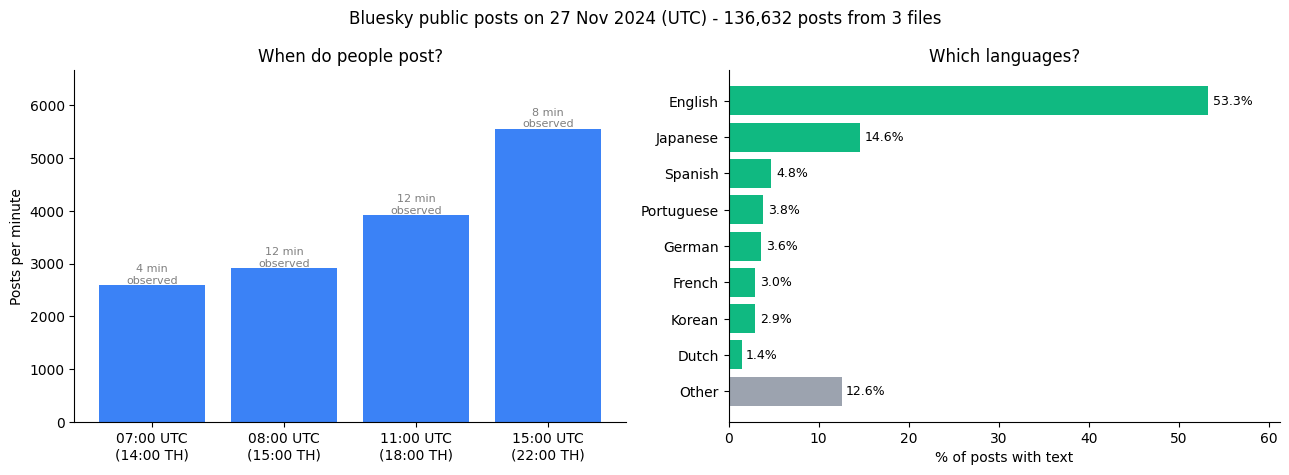

In [ ]:
# ===== ข้อ 4: Visualization 1 รูป =====
# (ป้ายกำกับในกราฟใช้ภาษาอังกฤษ เพราะฟอนต์เริ่มต้นของ matplotlib แสดงภาษาไทยไม่ได้)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# ซ้าย: ความถี่ในการโพสต์ของแต่ละชั่วโมง
ax = axes[0]
labels = [f"{h:02d}:00 UTC\n({(h + 7) % 24:02d}:00 TH)" for h in by_hour.index]
bars = ax.bar(labels, by_hour["posts_per_min"], color="#3b82f6")
for b, m in zip(bars, by_hour["minutes"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{m} min\nobserved",
            ha="center", va="bottom", fontsize=8, color="gray")
ax.set_ylim(0, by_hour["posts_per_min"].max() * 1.2)
ax.set_ylabel("Posts per minute")
ax.set_title("When do people post?")
ax.spines[["top", "right"]].set_visible(False)

# ขวา: สัดส่วนภาษา
ax = axes[1]
top_lang = lang_tab.head(8)
share = pd.concat([pd.Series(top_lang["share"].values, index=top_lang["language"]),
                   pd.Series({"Other": 1 - top_lang["share"].sum()})])[::-1] * 100
ax.barh(share.index, share.values, color=["#9ca3af"] + ["#10b981"] * (len(share) - 1))
for y, v in enumerate(share.values):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, share.max() * 1.15)
ax.set_xlabel("% of posts with text")
ax.set_title("Which languages?")
ax.spines[["top", "right"]].set_visible(False)

day = live["ts"].min().strftime("%d %b %Y")
fig.suptitle(f"Bluesky public posts on {day} (UTC) - {n_live:,} posts from {len(FILES)} files", fontsize=12)
fig.tight_layout()
fig.savefig("bluesky_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**<สรุปสั้น ๆ ถึงลูกค้า 5 บรรทัด>**
1. เมื่อไร: คนโพสต์ถี่ที่สุดช่วง 22:00 น. เวลาไทย (15:00 UTC) ราว 5,554 โพสต์/นาที เกือบ 2 เท่าของช่วง 15:00 น.
2. ภาษา: อังกฤษ 53% ญี่ปุ่น 15% จึงควรทำคอนเทนต์ภาษาอังกฤษก่อน แล้วค่อยเพิ่มภาษาญี่ปุ่น
3. หัวข้อ: คนคุยเรื่องศิลปะ หนังสือ และภาพถ่าย (#art, #booksky, #photography) กระแสเด่นของวันคือ book challenge
4. ข้อควรระวัง: มีเพียง 8.4% ที่ใช้ hashtag และ #nsfw ติดอันดับ 3 จึงควรคัดกรองก่อนนำแบรนด์ไปเกาะกระแส
5. ข้อจำกัด: เป็นข้อมูล 136,632 โพสต์ใน 36 นาทีของวันเดียว (27 พ.ย. 2567) ใช้เป็นภาพรวมเบื้องต้นเท่านั้น